<a href="https://colab.research.google.com/github/dewi-ikrimah/Proyek-Akhir-Pembelajaran-Mesin/blob/main/EDA_Stroke_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Langkah 1 - Muat data dengan benar**

In [ ]:

import pandas as pd

# 1. Menentukan nama file dataset
nama_berkas = "healthcare-dataset-stroke-data.csv"

# 2. Memuat dataset
df = pd.read_csv(
    nama_berkas,
    sep=",",
    encoding="utf-8",
    na_values=["?", "---", "NA", "N/A", "n/a"],
    skipinitialspace=True
)

# 3. Memeriksa nama file
print("Nama file:", nama_berkas)

# 4. Memeriksa ukuran dataset
print("\nUkuran dataset (baris, kolom):", df.shape)

# 5. Memeriksa jumlah kolom
print("\nJumlah kolom:", len(df.columns))

# 6. Memeriksa nama-nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

# 7. Menampilkan lima baris pertama
print("\nLima baris pertama dataset:")
display(df.head())

# 8. Memeriksa apakah pemisah kolom terbaca dengan benar
if df.shape[1] > 1:
    print("\nPemeriksaan pemisah kolom: BERHASIL")
else:
    print("\nPemeriksaan pemisah kolom: PERLU DIPERIKSA")


Nama file: healthcare-dataset-stroke-data.csv

Ukuran dataset (baris, kolom): (5110, 12)

Jumlah kolom: 12

Nama kolom:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Lima baris pertama dataset:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



Pemeriksaan pemisah kolom: BERHASIL


Dataset punya 5.110 baris dan 12 kolom: id, gender, age, hypertension, heart_disease, ever_married, work_type, Residence_type, avg_glucose_level, bmi, smoking_status, stroke. Pemisah kolom terbaca benar (BERHASIL). Jika pemisah salah, seluruh data akan menumpuk dalam satu kolom.

**Langkah 2 - Potret struktur dan tetapkan unit analisis**

In [ ]:

# 1. Melihat ukuran dataset
print("Ukuran dataset (baris, kolom):")
print(df.shape)


# 2. Melihat 10 baris pertama
print("\nSepuluh baris pertama dataset:")
display(df.head(10))


# 3. Melihat informasi struktur dataset
print("\nInformasi struktur dataset:")
df.info()


# 4. Melihat ringkasan statistik kolom numerik
print("\nRingkasan statistik kolom numerik:")
display(df.describe())


# 5. Melihat ringkasan statistik kolom kategorikal
print("\nRingkasan statistik kolom kategorikal:")
display(df.describe(include="object"))


Ukuran dataset (baris, kolom):
(5110, 12)

Sepuluh baris pertama dataset:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1



Informasi struktur dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Ringkasan statistik kolom numerik:


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000



Ringkasan statistik kolom kategorikal:


,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


Unit analisis. Satu baris data mewakili satu pasien, yang dibedakan oleh id. Variabel target adalah stroke (0 = tidak stroke, 1 = stroke), sedangkan variabel lainnya adalah faktor demografis dan klinis yang diduga berhubungan dengan stroke. Kolom hypertension, heart_disease, dan stroke bertipe angka tetapi sebenarnya kategori biner (0/1).

**Langkah 3 - Periksa kebersihan data**

a. Memeriksa nilai hilang

In [ ]:

# A. PEMERIKSAAN NILAI HILANG

hilang = pd.DataFrame({
    "jumlah": df.isna().sum(),
    "persen": (df.isna().mean() * 100).round(2)
}).sort_values("persen", ascending=False)

print("Jumlah dan persentase nilai hilang:")
display(hilang[hilang["jumlah"] > 0])


Jumlah dan persentase nilai hilang:


,jumlah,persen
bmi,201,3.93


Hasil pemeriksaan: Berdasarkan dataset Stroke Prediction, ditemukan sebanyak 201 nilai hilang pada kolom bmi atau sekitar 3,93% dari total 5.110 data. Sementara itu, kolom lainnya tidak memiliki nilai hilang.

b. Memeriksa data hilang yang tersamar

In [ ]:

# B. PEMERIKSAAN DATA HILANG YANG TERSAMAR

# 1. Memeriksa nilai nol pada kolom numerik
kolom_periksa_nol = [
    "age",
    "avg_glucose_level",
    "bmi"
]

print("Pemeriksaan nilai nol:")
for k in kolom_periksa_nol:
    print(k, "->", (df[k] == 0).sum(), "baris bernilai nol")


# 2. Memeriksa nilai unik pada kolom kategorikal
print("\nPemeriksaan nilai unik kolom kategorikal:")

for k in df.select_dtypes(include="object").columns:
    print("\n", k)
    print(df[k].value_counts(dropna=False))


Pemeriksaan nilai nol:
age -> 0 baris bernilai nol
avg_glucose_level -> 0 baris bernilai nol
bmi -> 0 baris bernilai nol

Pemeriksaan nilai unik kolom kategorikal:

 gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

 ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

 work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

 Residence_type
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

 smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


c. Memeriksa duplikat

In [ ]:

# C. PEMERIKSAAN DUPLIKAT

print("Baris identik seluruhnya:", df.duplicated().sum())

print("Identifier (id) berulang:", df["id"].duplicated().sum())


Baris identik seluruhnya: 0
Identifier (id) berulang: 0


d. Memeriksa kolom konstan dan identifier

In [ ]:

# D. PEMERIKSAAN KOLOM KONSTAN DAN IDENTIFIER

n = df.nunique()

print("Kolom konstan:")
print(list(n[n <= 1].index))

print("\nKolom hampir unik per baris:")
print(list(n[n > 0.9 * len(df)].index))


Kolom konstan:
[]

Kolom hampir unik per baris:
['id']


In [ ]:

# E. PEMERIKSAAN NILAI MUSTAHIL DAN PENCILAN

kolom_numerik = [
    "age",
    "avg_glucose_level",
    "bmi"
]

# 1. Melihat statistik dasar
print("Statistik kolom numerik:")
display(df[kolom_numerik].describe())


# 2. Memeriksa nilai minimum dan maksimum
print("\nNilai minimum dan maksimum:")

for k in kolom_numerik:
    print(
        k,
        "-> Minimum:", df[k].min(),
        "| Maksimum:", df[k].max()
    )


# 3. Menghitung kandidat pencilan menggunakan metode IQR
print("\nPemeriksaan kandidat pencilan dengan IQR:")

for k in kolom_numerik:
    Q1 = df[k].quantile(0.25)
    Q3 = df[k].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[k] < batas_bawah) |
        (df[k] > batas_atas)
    ).sum()

    print("\nKolom:", k)
    print("Batas bawah:", round(batas_bawah, 2))
    print("Batas atas:", round(batas_atas, 2))
    print("Jumlah kandidat pencilan:", jumlah_outlier)


Statistik kolom numerik:


,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000



Nilai minimum dan maksimum:
age -> Minimum: 0.08 | Maksimum: 82.0
avg_glucose_level -> Minimum: 55.12 | Maksimum: 271.74
bmi -> Minimum: 10.3 | Maksimum: 97.6

Pemeriksaan kandidat pencilan dengan IQR:

Kolom: age
Batas bawah: -29.0
Batas atas: 115.0
Jumlah kandidat pencilan: 0

Kolom: avg_glucose_level
Batas bawah: 21.98
Batas atas: 169.36
Jumlah kandidat pencilan: 627

Kolom: bmi
Batas bawah: 9.1
Batas atas: 47.5
Jumlah kandidat pencilan: 110


e. Memeriksa nilai mustahil dan pencilan

In [ ]:
print("Bentuk dataset:", df.shape)
display(df.head(10))
df.info() # tipe tiap kolom dan jumlah nilai tidak kosong
df.describe() # ringkasan kolom numerik
df.describe(include='object') # ringkasan kolom teks/kategori

Bentuk dataset: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


,gender,ever_married,work_type,Residence_type,smoking_status
count,5110,5110,5110,5110,5110
unique,3,2,5,2,4
top,Female,Yes,Private,Urban,never smoked
freq,2994,3353,2925,2596,1892


f. Memeriksa konsistensi label kategori

In [ ]:

# F. PEMERIKSAAN KONSISTENSI LABEL KATEGORI

kolom_kategori = df.select_dtypes(include="object").columns

# 1. Menampilkan kategori sebelum penyeragaman
print("Kategori sebelum penyeragaman:")

for k in kolom_kategori:
    print("\nKolom:", k)
    print(df[k].value_counts(dropna=False))


# 2. Menghilangkan spasi berlebih di awal dan akhir teks
for k in kolom_kategori:
    df[k] = df[k].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )


# 3. Menampilkan kategori setelah penyeragaman
print("\nKategori setelah penyeragaman:")

for k in kolom_kategori:
    print("\nKolom:", k)
    print(df[k].value_counts(dropna=False))


Kategori sebelum penyeragaman:

Kolom: gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Kolom: ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

Kolom: work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Kolom: Residence_type
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

Kolom: smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

Kategori setelah penyeragaman:

Kolom: gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Kolom: ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

Kolom: work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Ko

### Langkah 3 – Pemeriksaan Kebersihan Data (*Data Cleaning*)

Langkah ketiga dilakukan untuk memeriksa kualitas dan kebersihan dataset sebelum digunakan dalam proses analisis lebih lanjut. Pemeriksaan ini bertujuan untuk mengidentifikasi permasalahan pada data, seperti nilai hilang (*missing values*), nilai nol yang tidak wajar, data duplikat, kolom dengan nilai konstan, nilai pencilan (*outlier*), serta ketidakkonsistenan kategori.

Berdasarkan hasil pemeriksaan, diperoleh beberapa temuan sebagai berikut:

1. **Nilai Hilang (*Missing Values*)**  
   Ditemukan sebanyak 201 nilai hilang pada kolom `bmi` atau sekitar 3,93% dari total 5.110 data. Sementara itu, kolom lainnya tidak memiliki nilai hilang.

2. **Pemeriksaan Nilai Nol**  
   Tidak ditemukan nilai nol pada kolom `age`, `avg_glucose_level`, dan `bmi`. Hal ini menunjukkan bahwa tidak terdapat nilai nol pada ketiga kolom tersebut berdasarkan hasil pemeriksaan.

3. **Pemeriksaan Data Duplikat**  
   Hasil pemeriksaan menunjukkan bahwa tidak terdapat baris duplikat maupun duplikasi pada kolom `id`. Dengan demikian, tidak ditemukan data ganda berdasarkan pemeriksaan tersebut.

4. **Pemeriksaan Kolom Konstan dan Identitas**  
   Tidak ditemukan kolom dengan nilai konstan. Namun, kolom `id` memiliki nilai unik pada setiap baris sehingga berfungsi sebagai identitas pasien dan tidak digunakan sebagai fitur dalam proses clustering.

5. **Pemeriksaan Nilai Pencilan (*Outlier*)**  
   Pemeriksaan menggunakan metode *Interquartile Range* (IQR) menemukan kandidat outlier pada beberapa kolom numerik, terutama `avg_glucose_level` dan `bmi`. Nilai-nilai tersebut perlu dianalisis lebih lanjut untuk menentukan apakah merupakan kesalahan data atau memang mencerminkan kondisi pasien.

6. **Pemeriksaan Konsistensi Kategori**  
   Pada kolom kategorikal ditemukan kategori `Other` pada kolom `gender` sebanyak 1 data dan kategori `Unknown` pada kolom `smoking_status` sebanyak 1.544 data. Kedua kategori tersebut tetap dipertahankan karena dapat merepresentasikan informasi tertentu dan tidak langsung dianggap sebagai kesalahan data.


**Langkah 4 - Pahami variabel target sesuai metode kelompok Anda**

a. Menentukan fitur segmentasi

In [ ]:
# Menentukan fitur untuk segmentasi pasien

fitur_numerik = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi"
]

fitur_kategori = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

fitur_segmentasi = fitur_numerik + fitur_kategori

print("Fitur yang digunakan untuk segmentasi:")
print(fitur_segmentasi)

print("\nTipe data fitur:")
display(df[fitur_segmentasi].dtypes)

print("\nJumlah nilai unik setiap fitur:")
display(df[fitur_segmentasi].nunique())

Fitur yang digunakan untuk segmentasi:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

Tipe data fitur:


,0
age,float64
hypertension,int64
heart_disease,int64
avg_glucose_level,float64
bmi,float64
gender,object
ever_married,object
work_type,object
Residence_type,object
smoking_status,object



Jumlah nilai unik setiap fitur:


,0
age,104
hypertension,2
heart_disease,2
avg_glucose_level,3979
bmi,418
gender,3
ever_married,2
work_type,5
Residence_type,2
smoking_status,4


Pada langkah keempat, dilakukan pemahaman terhadap variabel yang akan digunakan dalam proses analisis berdasarkan metode yang dipilih oleh kelompok, yaitu *Clustering* menggunakan algoritma K-Means.

Berbeda dengan metode klasifikasi dan regresi, K-Means tidak menggunakan variabel target atau label sebagai acuan dalam pembentukan kelompok. Algoritma ini bekerja dengan mengelompokkan data berdasarkan kemiripan karakteristik antarobjek. Oleh karena itu, fokus utama pada tahap ini adalah menentukan fitur-fitur yang relevan untuk membentuk segmentasi profil pasien.


Fitur yang dipilih terdiri dari dua jenis, yaitu:

- **Fitur Numerik:**
  - `age`: usia pasien.
  - `hypertension`: status hipertensi pasien.
  - `heart_disease`: status penyakit jantung pasien.
  - `avg_glucose_level`: rata-rata kadar glukosa pasien.
  - `bmi`: indeks massa tubuh pasien.

- **Fitur Kategorikal:**
  - `gender`: jenis kelamin pasien.
  - `ever_married`: status pernikahan pasien.
  - `work_type`: jenis pekerjaan pasien.
  - `Residence_type`: jenis tempat tinggal pasien.
  - `smoking_status`: status merokok pasien.

Fitur-fitur tersebut dipilih karena dapat menggambarkan karakteristik demografis, kondisi kesehatan, serta gaya hidup pasien. Kombinasi karakteristik tersebut diharapkan dapat membantu proses pengelompokan pasien berdasarkan kemiripan profilnya.



b. Memeriksa pencilan dengan boxplot

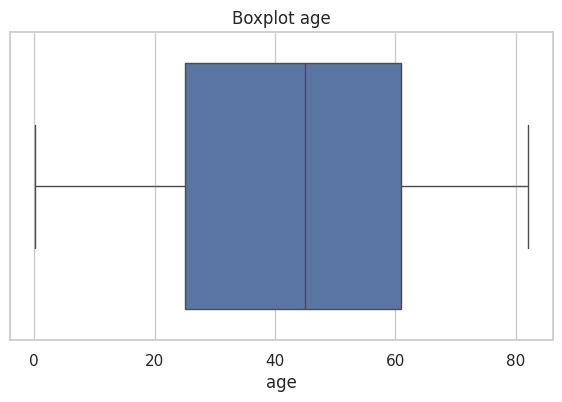

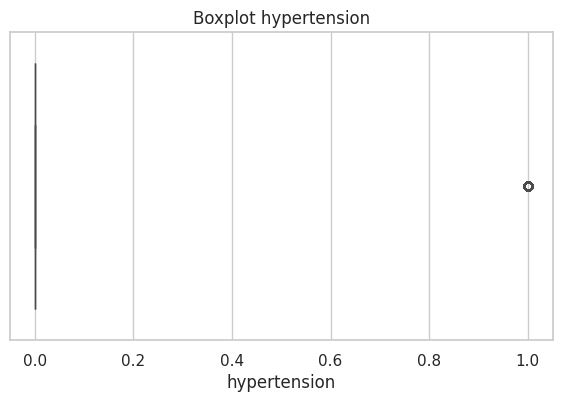

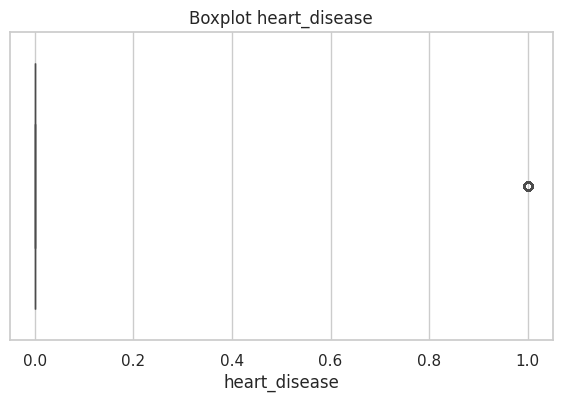

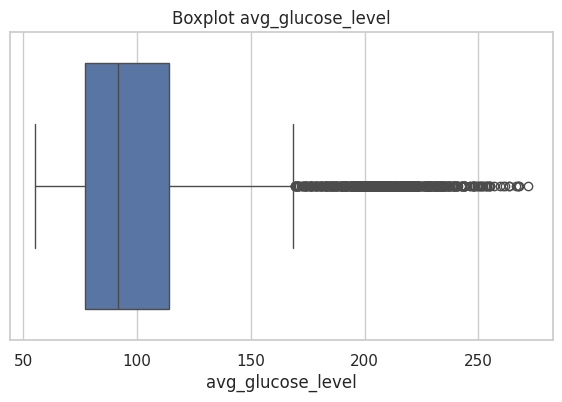

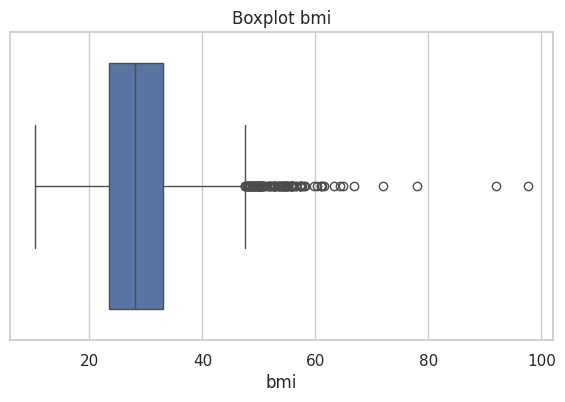

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat boxplot fitur numerik
for kolom in fitur_numerik:
    plt.figure(figsize=(7, 4))

    sns.boxplot(x=df[kolom])

    plt.title("Boxplot " + kolom)
    plt.xlabel(kolom)

    plt.show()

c. Menghitung kandidat pencilan dengan IQR

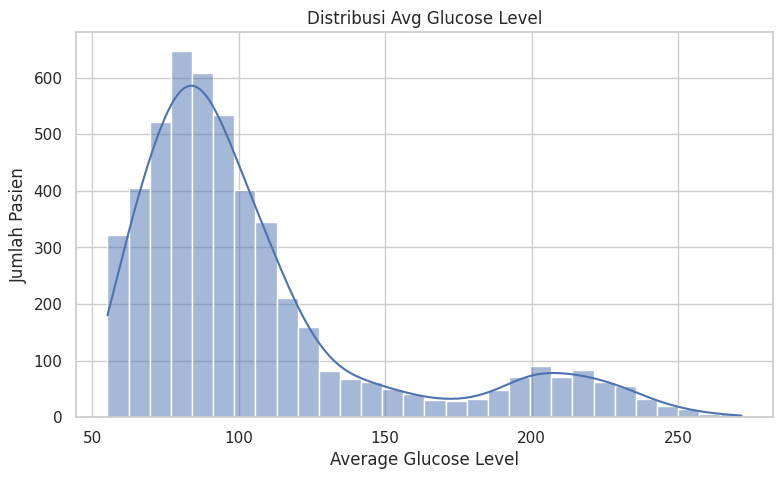

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='avg_glucose_level',
    bins=30,
    kde=True
)

plt.title('Distribusi Avg Glucose Level')
plt.xlabel('Average Glucose Level')
plt.ylabel('Jumlah Pasien')

plt.show()

d. Memeriksa distribusi fitur numerik

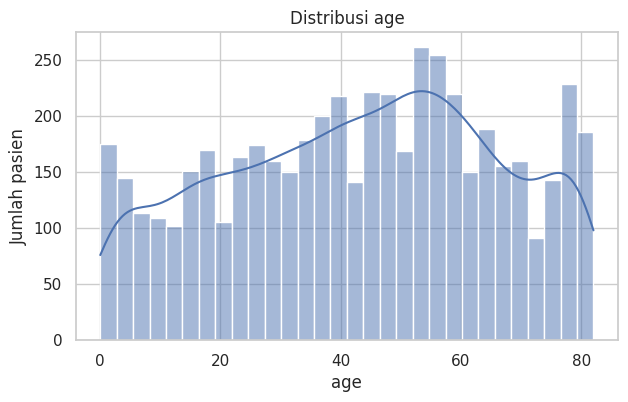

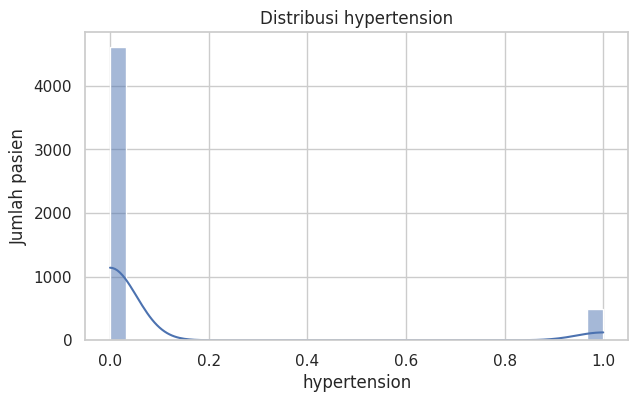

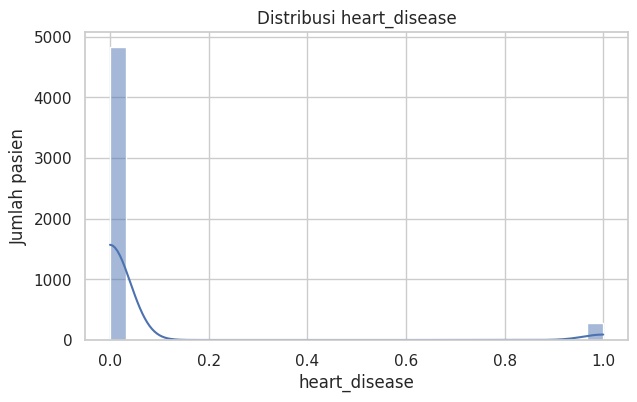

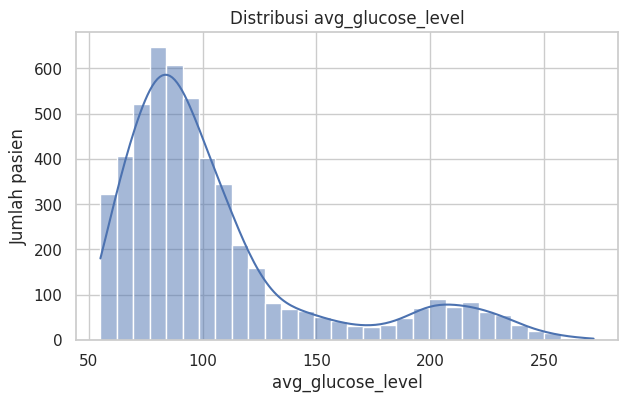

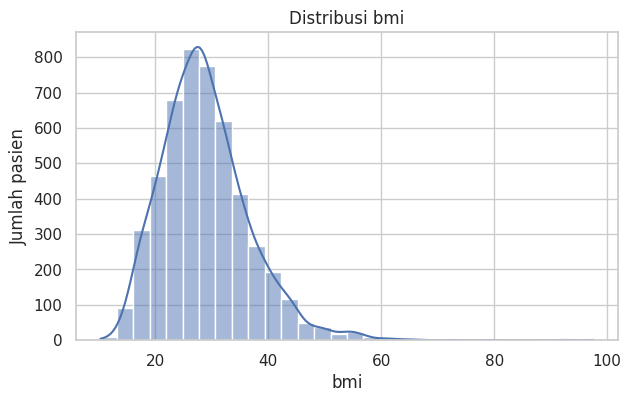

In [ ]:
# Membuat histogram fitur numerik

for kolom in fitur_numerik:
    plt.figure(figsize=(7, 4))

    sns.histplot(
        data=df,
        x=kolom,
        kde=True,
        bins=30
    )

    plt.title("Distribusi " + kolom)
    plt.xlabel(kolom)
    plt.ylabel("Jumlah pasien")

    plt.show()

e. Memeriksa distribusi fitur kategori

In [ ]:
# Menampilkan jumlah setiap kategori

for kolom in fitur_kategori:
    print("\nDistribusi kategori:", kolom)

    display(
        df[kolom]
        .value_counts(dropna=False)
        .to_frame("Jumlah pasien")
    )


Distribusi kategori: gender


,Jumlah pasien
gender,
Female,2994
Male,2115
Other,1



Distribusi kategori: ever_married


,Jumlah pasien
ever_married,
Yes,3353
No,1757



Distribusi kategori: work_type


,Jumlah pasien
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22



Distribusi kategori: Residence_type


,Jumlah pasien
Residence_type,
Urban,2596
Rural,2514



Distribusi kategori: smoking_status


,Jumlah pasien
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


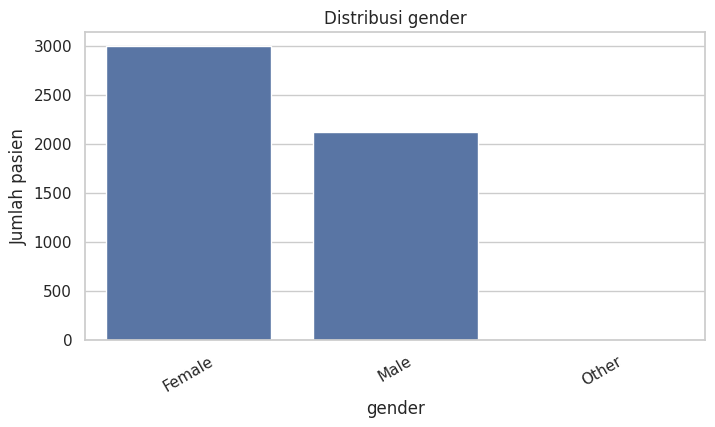

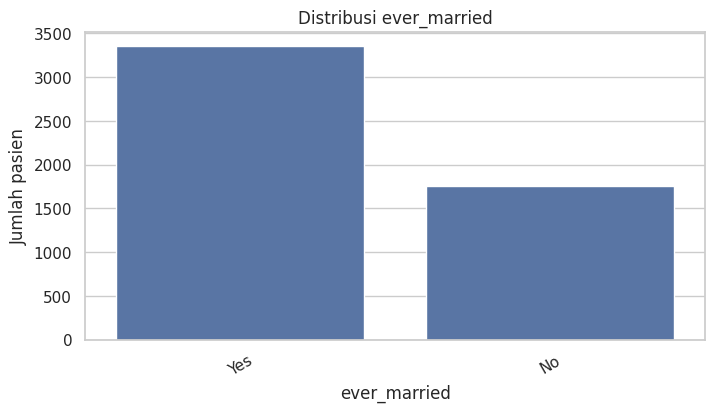

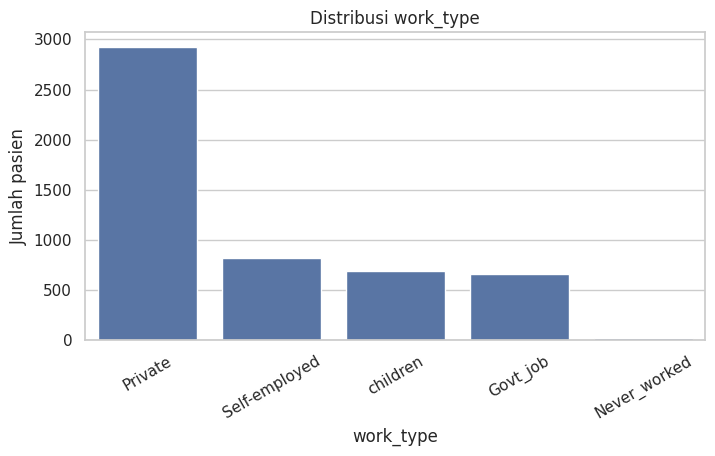

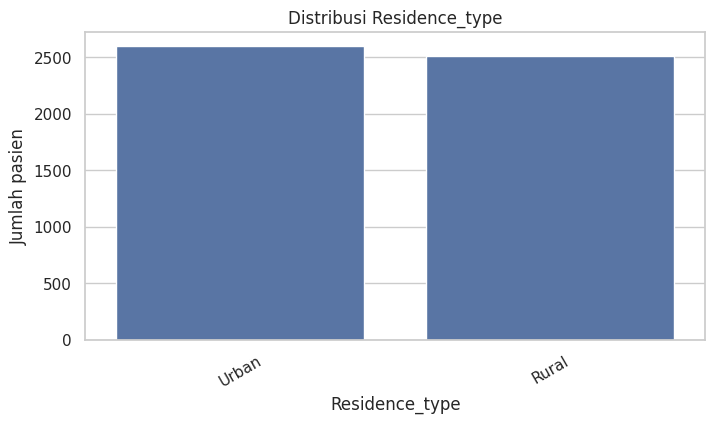

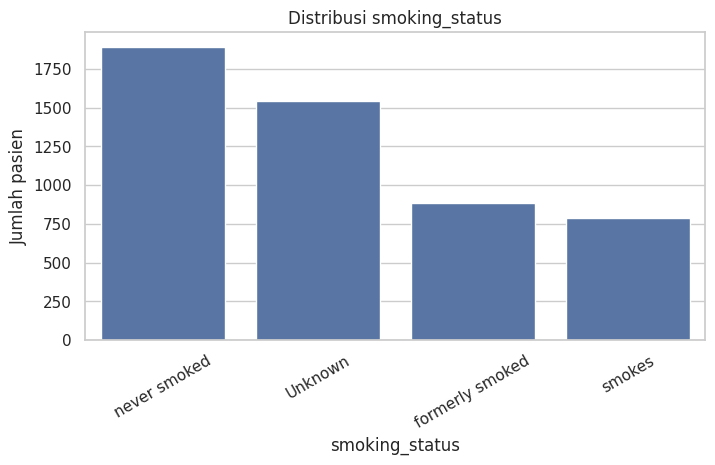

In [ ]:
# Membuat diagram batang fitur kategori

for kolom in fitur_kategori:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=kolom,
        order=df[kolom].value_counts().index
    )

    plt.title("Distribusi " + kolom)
    plt.xlabel(kolom)
    plt.ylabel("Jumlah pasien")
    plt.xticks(rotation=30)

    plt.show()

f. Memeriksa hubungan antarfitur numerik

Matriks korelasi antarfitur:


,age,hypertension,heart_disease,avg_glucose_level,bmi
age,1.00,0.28,0.26,0.24,0.33
hypertension,0.28,1.00,0.11,0.17,0.17
heart_disease,0.26,0.11,1.00,0.16,0.04
avg_glucose_level,0.24,0.17,0.16,1.00,0.18
bmi,0.33,0.17,0.04,0.18,1.00


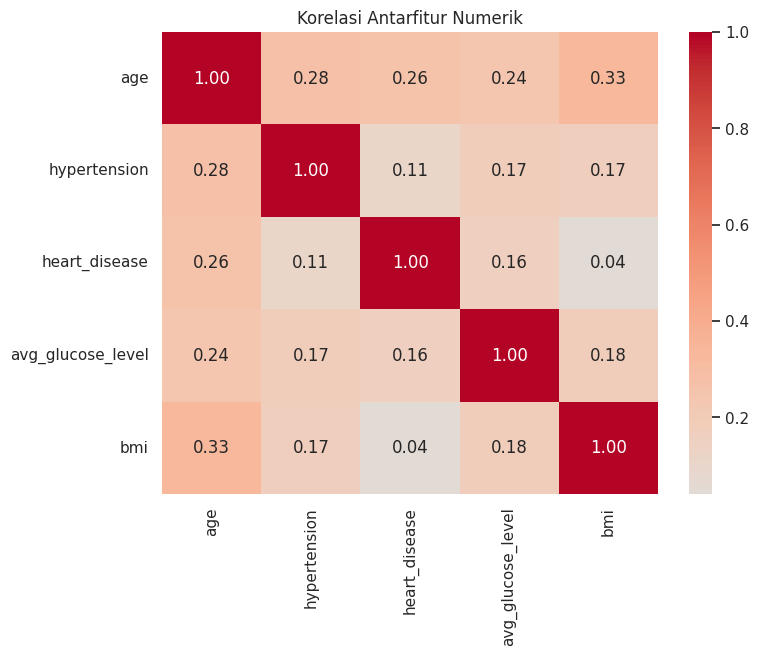

In [ ]:
# Menghitung korelasi antarfitur numerik

korelasi = df[fitur_numerik].corr()

print("Matriks korelasi antarfitur:")
display(korelasi.round(2))

# Membuat heatmap korelasi
plt.figure(figsize=(8, 6))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Korelasi Antarfitur Numerik")
plt.show()

### Memeriksa Hubungan Antarfitur Numerik

Pada tahap ini, dilakukan pemeriksaan hubungan atau korelasi antarfitur numerik menggunakan metode korelasi Pearson. Pemeriksaan ini bertujuan untuk mengetahui tingkat kekuatan dan arah hubungan linear antara masing-masing fitur numerik dalam dataset.

Perhitungan korelasi dilakukan menggunakan fungsi `corr()` pada fitur-fitur yang terdapat dalam variabel `fitur_numerik`. Hasil perhitungan kemudian ditampilkan dalam bentuk matriks korelasi dengan dua angka di belakang koma.

Selanjutnya, matriks korelasi divisualisasikan menggunakan *heatmap* dengan bantuan library Seaborn. Parameter `annot=True` digunakan untuk menampilkan nilai korelasi pada setiap sel, `cmap="coolwarm"` digunakan untuk membedakan tingkat korelasi melalui gradasi warna, sedangkan `center=0` menjadikan nilai nol sebagai titik tengah visualisasi.

Berdasarkan hasil matriks korelasi, diperoleh beberapa temuan sebagai berikut:

1. **Age dan BMI** memiliki korelasi positif sebesar 0,33. Hubungan ini merupakan korelasi tertinggi di antara pasangan fitur yang diperiksa.
2. **Age dan Hypertension** memiliki korelasi positif sebesar 0,28, yang menunjukkan adanya hubungan positif dengan kekuatan relatif lemah.
3. **Age dan Heart Disease** memiliki korelasi positif sebesar 0,26.
4. **Age dan Avg Glucose Level** memiliki korelasi positif sebesar 0,24.
5. **Heart Disease dan BMI** memiliki korelasi sebesar 0,04, yang menunjukkan hubungan linear yang sangat lemah.

Secara keseluruhan, nilai korelasi antarfitur berada pada rentang 0,04 hingga 0,33. Hal ini menunjukkan bahwa hubungan linear antarfitur numerik cenderung lemah dan tidak ditemukan hubungan yang sangat kuat antarvariabel.


**Langkah 5 - Periksa hubungan antar variabel dan cari kebocoran data**

a. Menentukan fitur yang diperiksa

In [ ]:
# Menentukan fitur yang digunakan dalam pemeriksaan Langkah 5

fitur_numerik = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi"
]

fitur_kategori = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

fitur_segmentasi = fitur_numerik + fitur_kategori

print("Fitur segmentasi:")
print(fitur_segmentasi)

Fitur segmentasi:
['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


Fitur dibagi menjadi dua kelompok:

* Numerik (5): age, hypertension, heart_disease, avg_glucose_level, bmi.
* Kategorikal (5): gender, ever_married, work_type, Residence_type, smoking_status.

Keduanya digabung menjadi fitur_segmentasi (10 fitur). id dan stroke sengaja tidak masuk.

b. Membuat matriks korelasi

In [ ]:
# Menghitung korelasi antarfitur numerik

korelasi = df[fitur_numerik].corr()

print("Matriks korelasi antarfitur numerik:")
display(korelasi.round(3))

Matriks korelasi antarfitur numerik:


,age,hypertension,heart_disease,avg_glucose_level,bmi
age,1.000,0.276,0.264,0.238,0.333
hypertension,0.276,1.000,0.108,0.174,0.168
heart_disease,0.264,0.108,1.000,0.162,0.041
avg_glucose_level,0.238,0.174,0.162,1.000,0.176
bmi,0.333,0.168,0.041,0.176,1.000


df[fitur_numerik].corr() menghitung korelasi Pearson antarfitur numerik. Semua korelasi positif dan lemah sampai sedang. Yang tertinggi adalah age–bmi (0,333), disusul age–hypertension (0,276) dan age–heart_disease (0,264). Yang terendah adalah heart_disease–bmi (0,041). Usia tampak menjadi faktor yang paling terkait dengan fitur lain.

c. Membuat heatmap korelasi

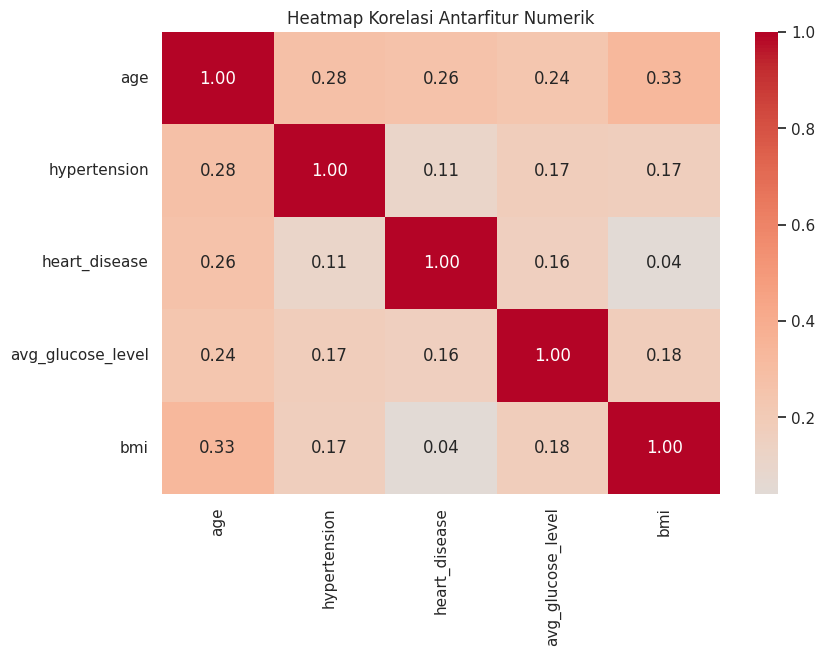

In [ ]:
# Visualisasi korelasi menggunakan heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Heatmap Korelasi Antarfitur Numerik")
plt.show()

Matriks korelasi divisualisasikan dengan sns.heatmap (annot=True menampilkan angka, cmap="coolwarm" dan center=0 membuat warna merah untuk korelasi positif dan biru untuk negatif). Visual ini memudahkan melihat pola hubungan sekilas, dan tidak ada sel yang menunjukkan korelasi sangat kuat.

d. Menemukan pasangan fitur dengan korelasi kuat

In [ ]:
# Mencari pasangan fitur dengan korelasi absolut di atas 0.8

import numpy as np

korelasi_kuat = []

for i in range(len(korelasi.columns)):
    for j in range(i + 1, len(korelasi.columns)):

        nilai = korelasi.iloc[i, j]

        if abs(nilai) > 0.8:
            korelasi_kuat.append({
                "Fitur 1": korelasi.columns[i],
                "Fitur 2": korelasi.columns[j],
                "Korelasi": round(nilai, 3)
            })

if korelasi_kuat:
    print("Pasangan fitur dengan korelasi di atas 0.8:")
    display(pd.DataFrame(korelasi_kuat))
else:
    print("Tidak ditemukan pasangan fitur dengan korelasi absolut di atas 0.8.")

Tidak ditemukan pasangan fitur dengan korelasi absolut di atas 0.8.


Kode memeriksa semua pasangan fitur dengan perulangan dan menyaring yang berkorelasi absolut di atas 0,8. Hasilnya tidak ada pasangan yang memenuhi. Artinya tidak ada fitur yang redundan, sehingga semua fitur numerik boleh dipertahankan.

e. Memeriksa identifier dan variabel yang tidak boleh menjadi fitur

In [ ]:
# Memeriksa kolom identifier dan variabel stroke

print("Jumlah nilai unik id:", df["id"].nunique())
print("Jumlah baris dataset:", len(df))

print("\nDistribusi stroke:")
display(df["stroke"].value_counts(dropna=False))

print("\nFitur yang tidak digunakan dalam pembentukan klaster:")
print(["id", "stroke"])

Jumlah nilai unik id: 5110
Jumlah baris dataset: 5110

Distribusi stroke:


,count
stroke,
0,4861
1,249



Fitur yang tidak digunakan dalam pembentukan klaster:
['id', 'stroke']


* id memiliki 5.110 nilai unik dari 5.110 baris, jadi hanya penanda pasien dan tidak bermakna sebagai fitur.
* stroke berdistribusi 4.861 tidak stroke (0) dan 249 stroke (1), sekitar 4,87% kasus positif.
* id dan stroke tidak dipakai dalam pembentukan klaster. id bukan karakteristik pasien, dan stroke adalah variabel hasil. Jika dimasukkan, informasi hasil akan “bocor” ke dalam pembentukan segmen.

f. Memeriksa hubungan fitur kategori

In [ ]:
# Memeriksa hubungan silang antarfitur kategori

pasangan_kategori = [
    ("gender", "ever_married"),
    ("work_type", "ever_married"),
    ("Residence_type", "work_type"),
    ("smoking_status", "gender")
]

for kolom1, kolom2 in pasangan_kategori:

    print("\nHubungan", kolom1, "dan", kolom2)

    tabel = pd.crosstab(
        df[kolom1],
        df[kolom2],
        normalize="index"
    ) * 100

    display(tabel.round(2))


Hubungan gender dan ever_married


ever_married,No,Yes
gender,,
Female,33.17,66.83
Male,36.08,63.92
Other,100.00,0.00



Hubungan work_type dan ever_married


ever_married,No,Yes
work_type,,
Govt_job,17.81,82.19
Never_worked,100.00,0.00
Private,28.07,71.93
Self-employed,13.43,86.57
children,100.00,0.00



Hubungan Residence_type dan work_type


work_type,Govt_job,Never_worked,Private,Self-employed,children
Residence_type,,,,,
Rural,12.41,0.28,58.15,15.63,13.52
Urban,13.29,0.58,56.36,16.41,13.37



Hubungan smoking_status dan gender


gender,Female,Male,Other
smoking_status,,,
Unknown,54.15,45.85,0.00
formerly smoked,53.90,45.99,0.11
never smoked,64.96,35.04,0.00
smokes,57.29,42.71,0.00


Kode membuat tabel silang pd.crosstab(..., normalize="index") * 100, yaitu persentase per baris, untuk empat pasangan:

* gender × ever_married: proporsi menikah mirip antara perempuan (66,83%) dan laki-laki (63,92%). Satu data “Other” belum menikah, tetapi jumlahnya terlalu kecil untuk disimpulkan.
* work_type × ever_married: children dan Never_worked 100% belum menikah. Self-employed paling tinggi menikah (86,57%). Terlihat jelas bahwa tipe pekerjaan berkaitan dengan usia dan status pernikahan.
* Residence_type × work_type: distribusi pekerjaan hampir sama antara Rural dan Urban, jadi keduanya tidak saling berkaitan kuat.
* smoking_status × gender: never smoked lebih banyak perempuan (64,96%) dibanding kategori merokok lain.

**Langkah 6 - Visualisasi yang menjawab pertanyaan**

a. Import library dan menentukan fitur

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Fitur numerik untuk segmentasi pasien
fitur_numerik = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi"
]

# Fitur kategorikal untuk segmentasi pasien
fitur_kategori = [
    "gender",
    "ever_married",
    "work_type",
    "Residence_type",
    "smoking_status"
]

sns.set_theme(style="whitegrid")

b. Histogram usia pasien

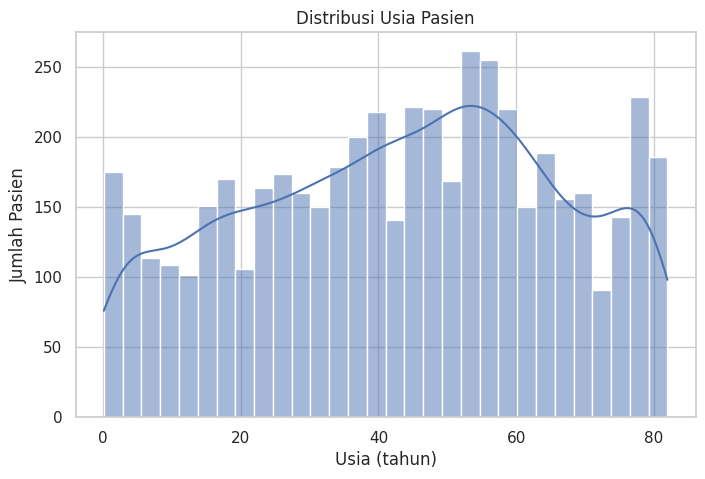

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Distribusi Usia Pasien")
plt.xlabel("Usia (tahun)")
plt.ylabel("Jumlah Pasien")

plt.show()

sns.histplot dengan bins=30 membagi usia ke 30 interval, dan kde=True menambah garis kepadatan halus. Sumbu X adalah usia, sumbu Y jumlah pasien. Sebarannya tidak simetris dan tidak seperti lonceng: jumlah pasien naik dari usia muda, mencapai puncak di sekitar usia 50–58 tahun (sekitar 250 pasien per interval), turun, lalu naik lagi di usia 75–80 tahun. Pasien tersebar dari bayi sampai lansia, sehingga dataset mencakup semua kelompok usia.

c. Histogram kadar glukosa

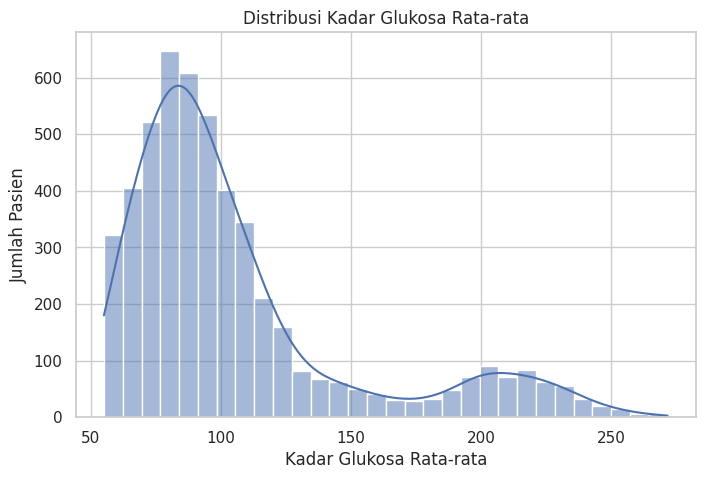

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="avg_glucose_level",
    bins=30,
    kde=True
)

plt.title("Distribusi Kadar Glukosa Rata-rata")
plt.xlabel("Kadar Glukosa Rata-rata")
plt.ylabel("Jumlah Pasien")

plt.show()

Pengaturannya sama dengan histogram usia, tetapi untuk avg_glucose_level. Sebaran condong ke kanan dan punya dua puncak. Puncak utama ada di sekitar 80–100 (kadar normal), lalu muncul puncak kecil kedua di sekitar 200–220. Puncak kedua ini diduga kelompok pasien berkadar glukosa tinggi (misalnya penderita diabetes), dan menjelaskan mengapa ada 627 kandidat pencilan di Langkah 3. Nilai-nilai tinggi ini punya makna klinis, jadi tidak otomatis dianggap kesalahan.

d. Histogram BMI

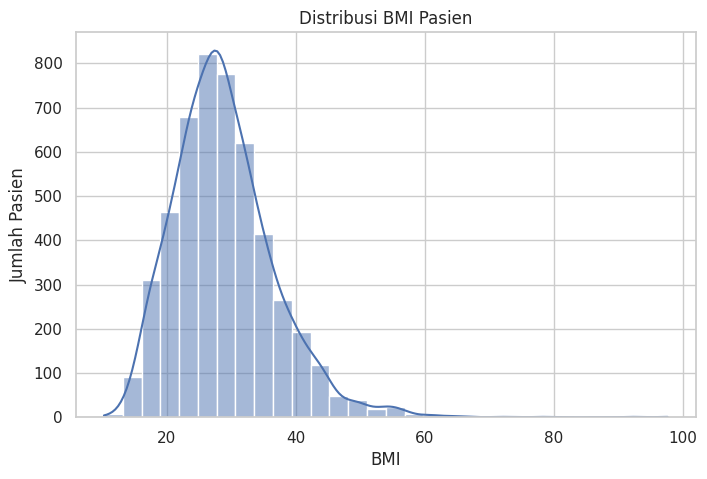

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="bmi",
    bins=30,
    kde=True
)

plt.title("Distribusi BMI Pasien")
plt.xlabel("BMI")
plt.ylabel("Jumlah Pasien")

plt.show()

Grafik yang sama untuk bmi. Sebarannya mendekati lonceng dengan ekor panjang ke kanan. Mayoritas pasien ada di BMI 20–40 dengan puncak di sekitar 27–28, dan sangat sedikit pasien di atas 60. Titik di dekat 97,6 sangat jauh dari kelompok utama, sehingga patut dicurigai sebagai pencilan atau kesalahan input.

e. Boxplot fitur numerik

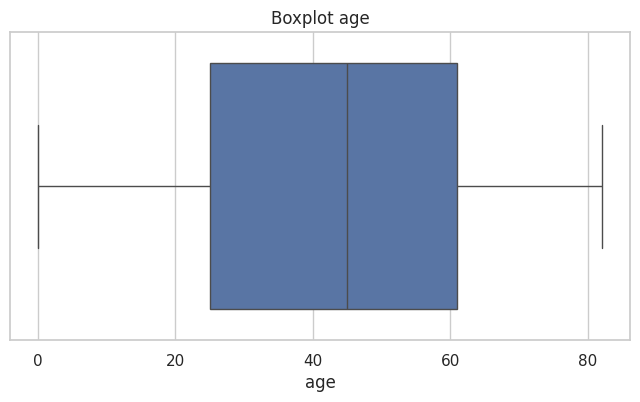

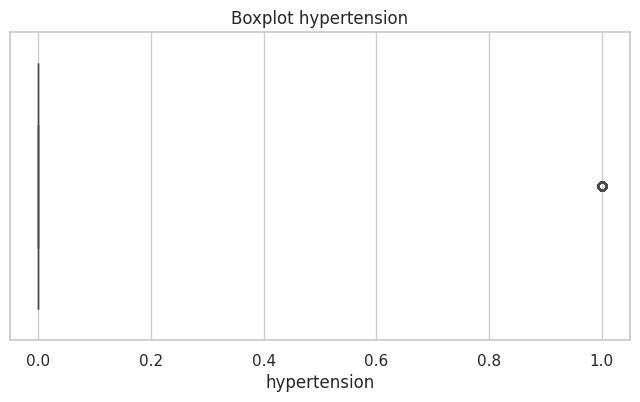

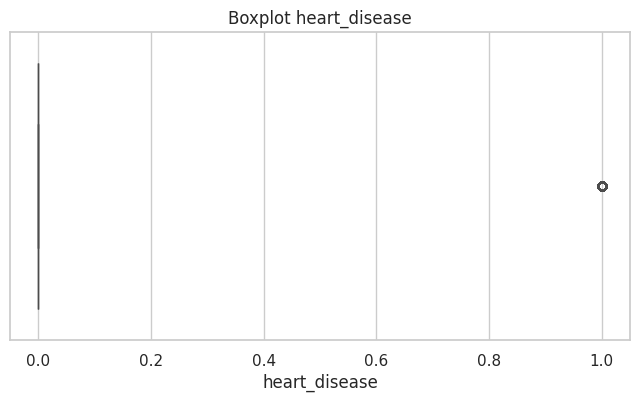

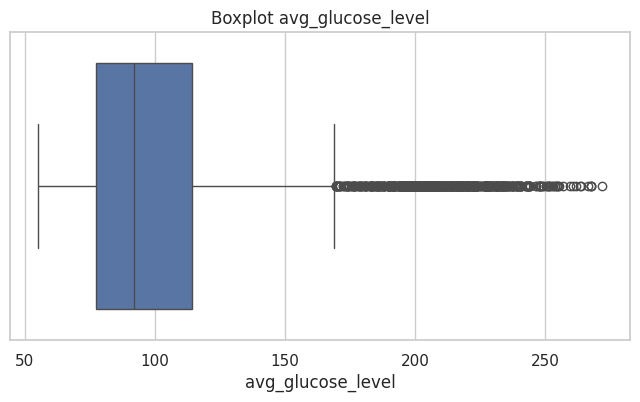

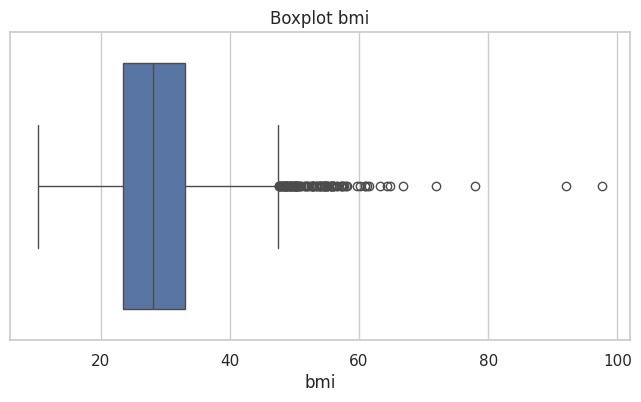

In [ ]:
for kolom in fitur_numerik:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=kolom)

    plt.title("Boxplot " + kolom)
    plt.xlabel(kolom)

    plt.show()

In [ ]:
# Menghapus kolom id jika masih tersedia
if 'id' in df.columns:
    df = df.drop(columns=['id'])
    print("Kolom ID berhasil dihapus.")
else:
    print("Kolom ID sudah tidak tersedia.")

print("\nDaftar kolom setelah pengecekan:")

for nomor, nama_kolom in enumerate(df.columns, start=1):
    print(f"{nomor}. {nama_kolom}")

print("\nJumlah baris dan kolom:", df.shape)

Kolom ID berhasil dihapus.

Daftar kolom setelah pengecekan:
1. gender
2. age
3. hypertension
4. heart_disease
5. ever_married
6. work_type
7. Residence_type
8. avg_glucose_level
9. bmi
10. smoking_status
11. stroke

Jumlah baris dan kolom: (5110, 11)


f. Diagram sebar usia dan kadar glukosa

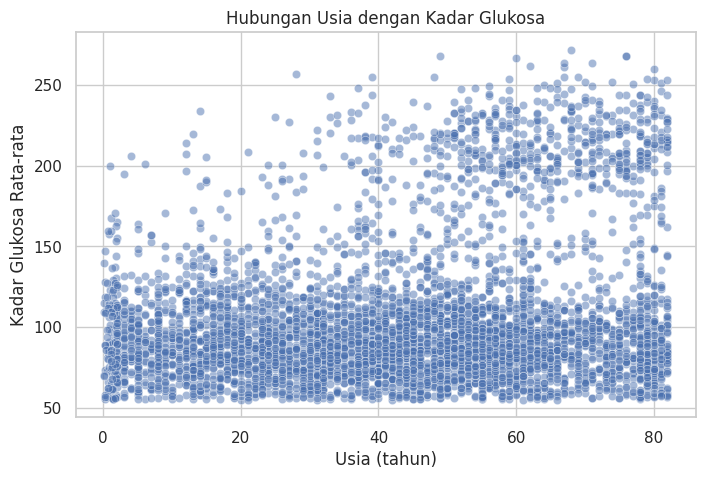

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="avg_glucose_level",
    alpha=0.5
)

plt.title("Hubungan Usia dengan Kadar Glukosa")
plt.xlabel("Usia (tahun)")
plt.ylabel("Kadar Glukosa Rata-rata")

plt.show()

g. Heatmap korelasi antarfitur

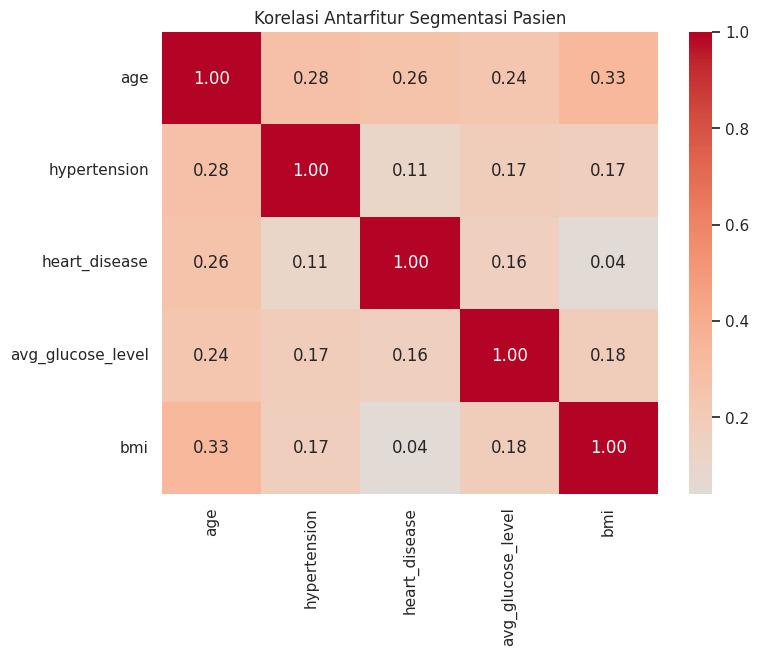

In [ ]:
korelasi = df[fitur_numerik].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    korelasi,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Korelasi Antarfitur Segmentasi Pasien")

plt.show()

h. Diagram batang fitur kategorikal

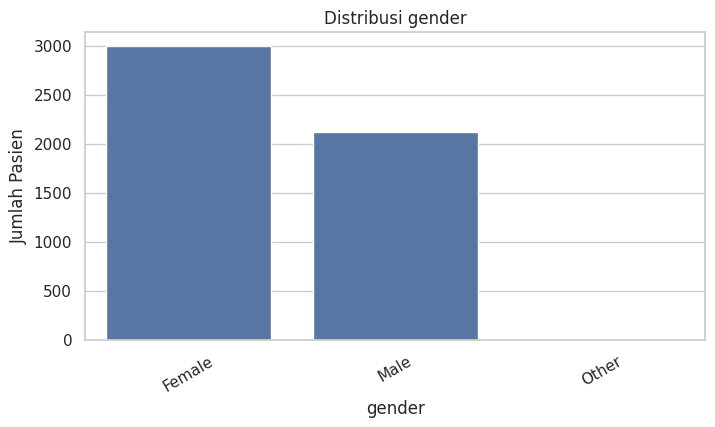

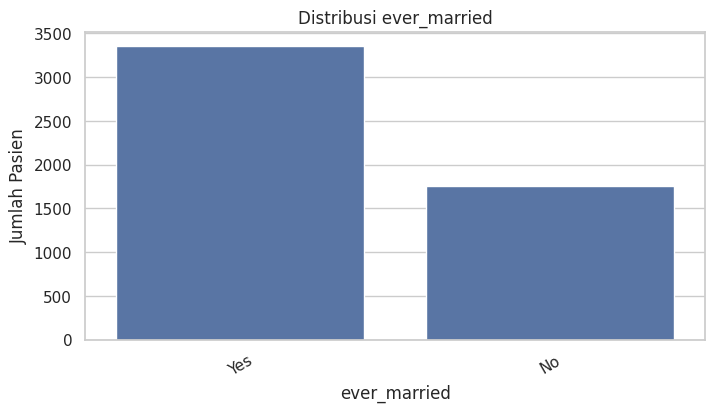

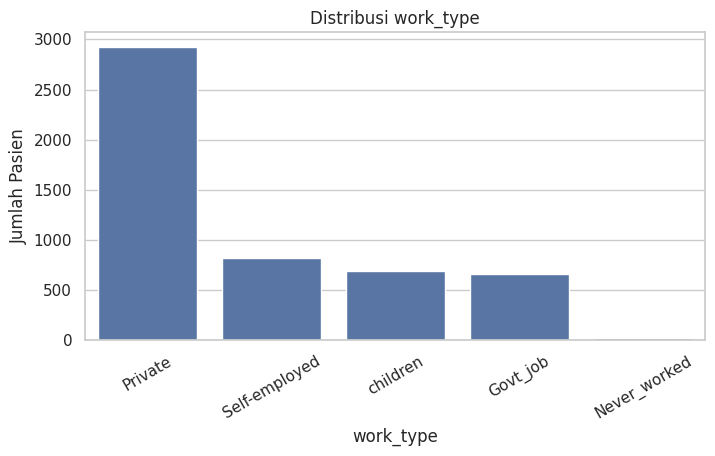

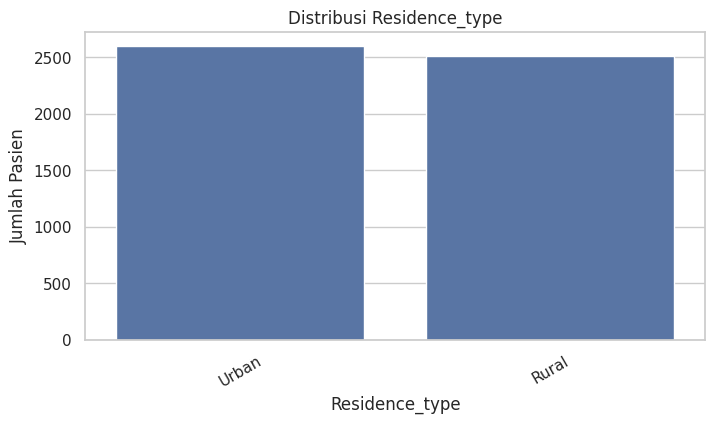

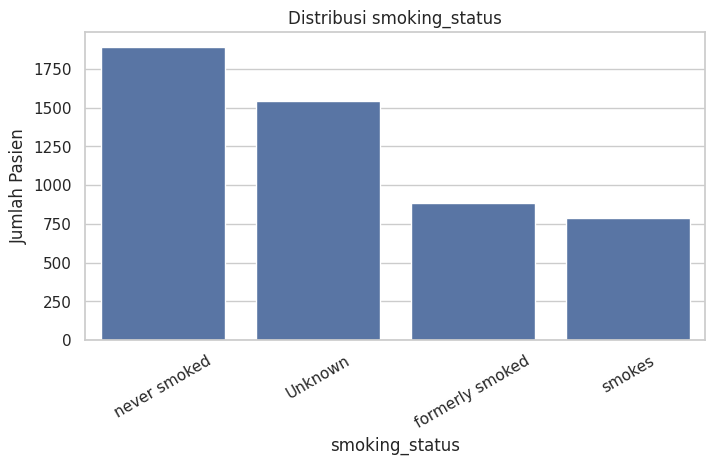

In [ ]:
for kolom in fitur_kategori:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=kolom,
        order=df[kolom].value_counts().index
    )

    plt.title("Distribusi " + kolom)
    plt.xlabel(kolom)
    plt.ylabel("Jumlah Pasien")
    plt.xticks(rotation=30)

    plt.show()

**Langkah 7 - Catat Keputusan dan Simpan Data Bersih**


a. Kode tabel keputusan preprocessing

In [ ]:



# Membuat tabel keputusan preprocessing
keputusan = [
    {
        "Kolom / Baris": "id",
        "Temuan": "Kolom berisi nomor identitas pasien yang unik",
        "Keputusan": "Dihapus dari fitur",
        "Alasan": "ID hanya berfungsi sebagai identifier dan tidak menggambarkan karakteristik pasien",
        "Baris Terpengaruh": "0 baris, 1 kolom"
    },
    {
        "Kolom / Baris": "bmi",
        "Temuan": "Terdapat nilai kosong (NaN)",
        "Keputusan": "Nilai kosong diisi menggunakan median",
        "Alasan": "Median lebih tahan terhadap pengaruh nilai ekstrem dibandingkan rata-rata",
        "Baris Terpengaruh": "Sesuai jumlah nilai kosong yang ditemukan"
    },
    {
        "Kolom / Baris": "smoking_status",
        "Temuan": "Terdapat kategori Unknown",
        "Keputusan": "Dipertahankan sebagai kategori tersendiri",
        "Alasan": "Unknown menunjukkan informasi status merokok yang tidak diketahui dan tidak boleh dianggap sebagai kategori yang diketahui",
        "Baris Terpengaruh": "Sesuai jumlah nilai Unknown yang ditemukan"
    },
    {
        "Kolom / Baris": "gender",
        "Temuan": "Terdapat satu data dengan kategori Other",
        "Keputusan": "Diperiksa dan dipertahankan apabila valid",
        "Alasan": "Kategori Other tidak otomatis merupakan kesalahan data",
        "Baris Terpengaruh": "Sesuai jumlah kategori Other"
    },
    {
        "Kolom / Baris": "Duplikat",
        "Temuan": "Diperiksa kemungkinan baris yang sama",
        "Keputusan": "Duplikat identik dihapus jika ditemukan",
        "Alasan": "Menghindari pengulangan data yang dapat memengaruhi hasil analisis",
        "Baris Terpengaruh": "Sesuai jumlah duplikat yang ditemukan"
    },
    {
        "Kolom / Baris": "Kolom konstan",
        "Temuan": "Diperiksa kolom dengan satu nilai unik",
        "Keputusan": "Kolom konstan dihapus jika ditemukan",
        "Alasan": "Kolom konstan tidak memberikan informasi untuk proses pengelompokan",
        "Baris Terpengaruh": "0 baris, sesuai jumlah kolom konstan"
    }
]

tabel_keputusan = pd.DataFrame(keputusan)

# Menampilkan tabel
display(tabel_keputusan)


,Kolom / Baris,Temuan,Keputusan,Alasan,Baris Terpengaruh
0,id,Kolom berisi nomor identitas pasien yang unik,Dihapus dari fitur,ID hanya berfungsi sebagai identifier dan tida...,"0 baris, 1 kolom"
1,bmi,Terdapat nilai kosong (NaN),Nilai kosong diisi menggunakan median,Median lebih tahan terhadap pengaruh nilai eks...,Sesuai jumlah nilai kosong yang ditemukan
2,smoking_status,Terdapat kategori Unknown,Dipertahankan sebagai kategori tersendiri,Unknown menunjukkan informasi status merokok y...,Sesuai jumlah nilai Unknown yang ditemukan
3,gender,Terdapat satu data dengan kategori Other,Diperiksa dan dipertahankan apabila valid,Kategori Other tidak otomatis merupakan kesala...,Sesuai jumlah kategori Other
4,Duplikat,Diperiksa kemungkinan baris yang sama,Duplikat identik dihapus jika ditemukan,Menghindari pengulangan data yang dapat memeng...,Sesuai jumlah duplikat yang ditemukan
5,Kolom konstan,Diperiksa kolom dengan satu nilai unik,Kolom konstan dihapus jika ditemukan,Kolom konstan tidak memberikan informasi untuk...,"0 baris, sesuai jumlah kolom konstan"


Dibuat tabel yang mencatat setiap masalah data beserta keputusan dan alasannya:

* id dihapus dari fitur karena hanya identifier, bukan karakteristik pasien.
* bmi yang kosong diisi median karena median lebih tahan terhadap nilai ekstrem.
* smoking_status kategori “Unknown” dipertahankan sebagai kategori tersendiri karena artinya memang tidak diketahui.
* gender kategori “Other” (1 baris) dipertahankan jika valid karena belum tentu kesalahan data.
* Duplikat identik dihapus jika ada, agar tidak memengaruhi hasil analisis.
* Kolom konstan dihapus jika ada, karena tidak memberi informasi.




b. Membuat dataset bersih

In [ ]:

# Menyimpan dataset bersih
OUTPUT_DATA = "data_bersih.csv"

df_bersih.to_csv(OUTPUT_DATA, index=False)

print("Dataset bersih berhasil disimpan:", OUTPUT_DATA)

# Menampilkan ukuran dataset
print("Ukuran dataset awal  :", df.shape)
print("Ukuran dataset bersih:", df_bersih.shape)


Dataset bersih berhasil disimpan: data_bersih.csv
Ukuran dataset awal  : (5110, 11)
Ukuran dataset bersih: (5110, 11)


Dataset yang sudah diproses disimpan ke data_bersih.csv dengan index=False agar nomor indeks tidak ikut tersimpan. Ukuran data dibandingkan: awal (5.110, 12) dan bersih (5.110, 11). Baris tetap karena tidak ada duplikat, sedangkan kolom berkurang satu karena id dihapus.

c. Menyimpan kamus data

In [ ]:

OUTPUT_DICT = "kamus_data.csv"

kamus_data.to_csv(OUTPUT_DICT, index=False)

print("Kamus data berhasil disimpan:", OUTPUT_DICT)


Kamus data berhasil disimpan: kamus_data.csv


,Nama Kolom,Tipe Data,Keterangan
0,gender,Kategorikal,"Jenis kelamin pasien (Female, Male, Other)"
1,age,Numerik,Usia pasien dalam tahun
2,hypertension,Kategori Biner (0/1),"Status hipertensi (0 = tidak memiliki, 1 = mem..."
3,heart_disease,Kategori Biner (0/1),"Status penyakit jantung (0 = tidak memiliki, 1..."
4,ever_married,Kategorikal,"Status pernikahan (Yes, No)"
5,work_type,Kategorikal,"Jenis pekerjaan (Private, Self-employed, Govt_..."
6,Residence_type,Kategorikal,"Jenis tempat tinggal (Urban, Rural)"
7,avg_glucose_level,Numerik,Rata-rata kadar glukosa dalam darah
8,bmi,Numerik,Indeks Massa Tubuh (Body Mass Index)
9,smoking_status,Kategorikal,"Status merokok (never smoked, formerly smoked,..."


Kamus data, yaitu tabel penjelasan setiap kolom, disimpan ke kamus_data.csv agar orang lain memahami isi dataset.

d. Menyimpan tabel keputusan ke CSV

In [ ]:

tabel_keputusan.to_csv(
    "tabel_keputusan_preprocessing.csv",
    index=False
)

print("Tabel keputusan berhasil disimpan.")


Tabel keputusan berhasil disimpan.


Tabel keputusan dari bagian a disimpan ke tabel_keputusan_preprocessing.csv sebagai arsip catatan pengolahan data.

e. Pemeriksaan akhir

In [ ]:

import os

daftar_file = [
    "data_bersih.csv",
    "kamus_data.csv",
    "tabel_keputusan_preprocessing.csv"
]

print("PEMERIKSAAN FILE OUTPUT")

for file in daftar_file:
    if os.path.exists(file):
        print(f"[OK] {file} - {os.path.getsize(file)} bytes")
    else:
        print(f"[BELUM ADA] {file}")


PEMERIKSAAN FILE OUTPUT
[OK] data_bersih.csv - 298392 bytes
[OK] kamus_data.csv - 815 bytes
[OK] tabel_keputusan_preprocessing.csv - 1224 bytes


Kode mengecek apakah ketiga file benar-benar ada dan berapa ukurannya. Hasilnya semua [OK]: data_bersih.csv (298.392 bytes), kamus_data.csv (333 bytes), dan tabel_keputusan_preprocessing.csv (1.224 bytes).